# Gemma 3 inference and step-level likelihoods

This notebook signs in to Hugging Face, loads `google/gemma-3-1b-it`, performs a generation sanity check using only the question, and scores each labeled step of the supplied answer.

For each answer step, the notebook reports:

- **Average likelihood:** arithmetic mean of the probabilities assigned to the step's tokens.
- **Average log likelihood:** arithmetic mean of the natural-log token probabilities.

Each token is scored causally given the prompt and all preceding answer tokens.

## 1. Authenticate and load the model

Gemma is a gated model. Before running this cell, accept its license on the [model page](https://huggingface.co/google/gemma-3-1b-it). If `HF_TOKEN` is set, it is used without displaying the token; otherwise an interactive Hugging Face login widget is shown.

In [1]:
import os
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import login
from IPython.display import Markdown, display
from transformers import AutoModelForCausalLM, AutoTokenizer
from dotenv import load_dotenv

load_dotenv("../secret.env")
assert os.environ.get("HF_TOKEN").startswith("hf_"), "No HF_TOKEN configured"
login()

In [2]:
MODEL_ID = "google/gemma-3-1b-it"

assert torch.cuda.is_available(), "Cuda not available"
dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
device_map = "auto"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    device_map=device_map,
)
if device_map is None:
    model = model.to("cpu")
model.eval()

print(f"Loaded {MODEL_ID} on {model.device} using {dtype}.")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

Loaded google/gemma-3-1b-it on cuda:0 using torch.bfloat16.


## 2. Sanity check: generate an answer from only the question

In [3]:
PROMPT = (
    "You are a math expert tasked with answering the following question. "
    "Write your answer in logical steps labeled 'Step 1: ...', 'Step 2: ...' and so on. "
    "On the last step, output just the final answer as a number prefixed with the string '####', "
    "so for example: 'Step 10: #### 42'.\n"
    "Question:\n"
    "A farmer is buying feed for his horses. "
    "He buys a variety of hay, oats, carrots and sugar cubes. "
    "Since sugar cubes are a rare treat, he only buys two 1-pound boxes of them for the whole stable. "
    "He only wants enough carrots to feed the horses while the vegetables are fresh, so he buys four 12-pound bags. "
    "Hay is the main diet of his horses, so he buys forty-two 75-pound bales. "
    "Oats are a staple to supplement the hay, so he buys twenty 65-pound sacks. "
    "If his farm truck can carry 2250 pounds at a time, how many trips does the farmer need to transport all the feed?\n"
    "Answer: \n"
)
ANSWER = (
    "Step 1: The farmer buys 2 boxes of sugar cubes * 16 pounds each = <<2*16=32>>32 pounds of sugar cubes.\n"
    "Step 2: He buys 4 bags of carrots * 12 pounds each = <<4*12=48>>48 pounds of carrots.\n"
    "Step 3: He buys 42 bales of hay * 75 pounds each = <<42*75=3100>>3100 pounds of hay.\n"
    "Step 4: He buys 20 sacks of oats * 65 pounds each = <<20*65=1300>>1300 pounds of oats.\n"
    "Step 5: He has 32 pounds of sugar cubes + 48 pounds of carrots + 3100 pounds of hay + 1300 pounds of oats = <<32+48+3100+1300=5170>>5170 pounds of feed to transport.\n"
    "Step 6: The farm truck can carry 2250 pounds * 5170/2250 = <<2250*5170/2250=2.5>>2.5 trips.\n"
    "Step 7: #### 2.5"
)
print(PROMPT + ANSWER)

You are a math expert tasked with answering the following question. Write your answer in logical steps labeled 'Step 1: ...', 'Step 2: ...' and so on. On the last step, output just the final answer as a number prefixed with the string '####', so for example: 'Step 10: #### 42'.
Question:
A farmer is buying feed for his horses. He buys a variety of hay, oats, carrots and sugar cubes. Since sugar cubes are a rare treat, he only buys two 1-pound boxes of them for the whole stable. He only wants enough carrots to feed the horses while the vegetables are fresh, so he buys four 12-pound bags. Hay is the main diet of his horses, so he buys forty-two 75-pound bales. Oats are a staple to supplement the hay, so he buys twenty 65-pound sacks. If his farm truck can carry 2250 pounds at a time, how many trips does the farmer need to transport all the feed?
Answer: 
Step 1: The farmer buys 2 boxes of sugar cubes * 16 pounds each = <<2*16=32>>32 pounds of sugar cubes.
Step 2: He buys 4 bags of carrot

In [4]:
messages = [{"role": "user", "content": PROMPT}]
generation_inputs = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
    return_tensors="pt",
    return_dict=True,
).to(model.device)

with torch.inference_mode():
    generated_ids = model.generate(
        **generation_inputs,
        max_new_tokens=256,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id,
    )

new_tokens = generated_ids[0, generation_inputs["input_ids"].shape[1]:]
generated_answer = tokenizer.decode(new_tokens, skip_special_tokens=False)
display(Markdown("### Generated answer\n" + generated_answer))

### Generated answer
Step 1: Calculate the total weight of the hay.
Hay: 42 bales * 75 pounds/bale = 3150 pounds

Step 2: Calculate the total weight of the oats.
Oats: 20 sacks * 65 pounds/sack = 1300 pounds

Step 3: Calculate the total weight of the carrots.
Carrots: 4 bags * 12 pounds/bag = 48 pounds

Step 4: Calculate the total weight of the vegetables.
Vegetables: 42 bales * 12 pounds/bale = 504 pounds

Step 5: Calculate the total weight of all the feed.
Total feed weight = 3150 pounds + 1300 pounds + 48 pounds + 504 pounds = 4992 pounds

Step 6: Determine the number of trips needed.
Truck capacity: 2250 pounds

Step 7: Divide the total weight by the truck capacity.
Number of trips = 4992 pounds / 2250 pounds/trip = 2.208 trips

Step 8: Round

## 3. Score each answer step

The prompt and answer are scored as one raw causal sequence so that each answer token is conditioned on the prompt and preceding steps. Character offsets from the fast tokenizer map predicted tokens to answer spans beginning with `Step N:`; prompt tokens are not included in the reported statistics.

In [5]:
def score_answer_steps(prompt, answer, tokenizer, model):
    if not getattr(tokenizer, "is_fast", False):
        raise ValueError("A fast tokenizer is required for character-to-token offsets.")

    step_matches = list(re.finditer(r"(?m)^Step\s+(\d+):", answer))
    if not step_matches:
        raise ValueError("The answer contains no spans labeled 'Step N:'.")

    text = prompt + answer
    answer_start = len(prompt)
    encoded = tokenizer(
        text,
        add_special_tokens=True,
        return_offsets_mapping=True,
        return_tensors="pt",
    )
    offsets = encoded.pop("offset_mapping")[0].tolist()
    model_inputs = {name: tensor.to(model.device) for name, tensor in encoded.items()}

    with torch.inference_mode():
        logits = model(**model_inputs).logits.float()

    # token_log_probs[k] is the log probability of input token k + 1.
    next_token_log_probs = torch.log_softmax(logits[:, :-1, :], dim=-1)
    target_ids = model_inputs["input_ids"][:, 1:]
    token_log_probs = next_token_log_probs.gather(
        dim=-1, index=target_ids.unsqueeze(-1)
    ).squeeze(0).squeeze(-1).cpu()

    rows = []
    for index, match in enumerate(step_matches):
        relative_start = match.start()
        relative_end = (
            step_matches[index + 1].start()
            if index + 1 < len(step_matches)
            else len(answer)
        )
        raw_step = answer[relative_start:relative_end]
        step_text = raw_step.strip()
        step_start = answer_start + relative_start
        step_end = step_start + len(raw_step.rstrip())

        # Position 0 has no preceding model logit. Special tokens have offset (0, 0).
        token_positions = [
            position
            for position, (start, end) in enumerate(offsets)
            if position > 0 and end > step_start and start < step_end and end > start
        ]
        if not token_positions:
            raise ValueError(f"No scoreable tokens found for step {match.group(1)}.")

        step_log_probs = torch.stack(
            [token_log_probs[position - 1] for position in token_positions]
        )
        rows.append(
            {
                "step": int(match.group(1)),
                "text": step_text,
                "tokens": len(token_positions),
                "average_likelihood": step_log_probs.exp().mean().item(),
                "average_log_likelihood": step_log_probs.mean().item(),
            }
        )

    return pd.DataFrame(rows)


scores = score_answer_steps(PROMPT, ANSWER, tokenizer, model)
display(
    scores.style.format(
        {
            "average_likelihood": "{:.6f}",
            "average_log_likelihood": "{:.4f}",
        }
    ).hide(axis="index")
)

step,text,tokens,average_likelihood,average_log_likelihood
1,Step 1: The farmer buys 2 boxes of sugar cubes * 16 pounds each = <<2*16=32>>32 pounds of sugar cubes.,36,0.705765,-2.4892
2,Step 2: He buys 4 bags of carrots * 12 pounds each = <<4*12=48>>48 pounds of carrots.,33,0.977006,-0.0390
3,Step 3: He buys 42 bales of hay * 75 pounds each = <<42*75=3100>>3100 pounds of hay.,39,0.973094,-0.2961
4,Step 4: He buys 20 sacks of oats * 65 pounds each = <<20*65=1300>>1300 pounds of oats.,39,0.998973,-0.0010
5,Step 5: He has 32 pounds of sugar cubes + 48 pounds of carrots + 3100 pounds of hay + 1300 pounds of oats = <<32+48+3100+1300=5170>>5170 pounds of feed to transport.,71,0.866246,-0.7076
6,Step 6: The farm truck can carry 2250 pounds * 5170/2250 = <<2250*5170/2250=2.5>>2.5 trips.,52,0.834667,-0.6736
7,Step 7: #### 2.5,9,0.788194,-1.8117


## 4. Visualize the two metrics by step

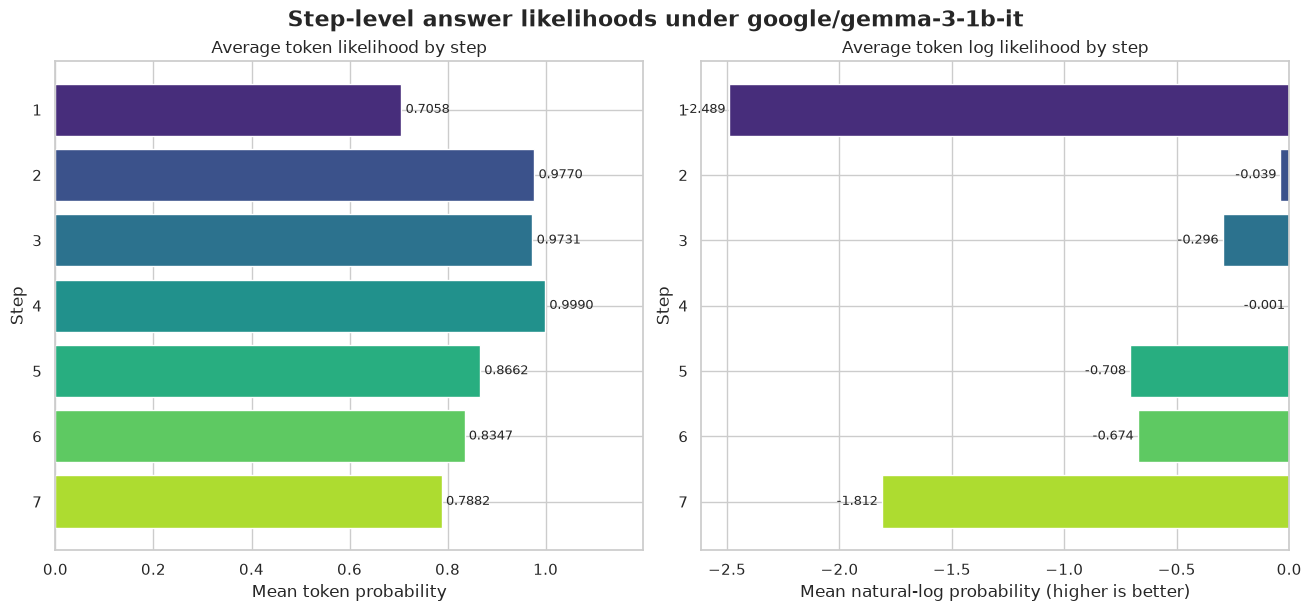

In [6]:
sns.set_theme(style="whitegrid", context="notebook")
plot_data = scores.copy()
plot_data["label"] = plot_data["step"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
palette = sns.color_palette("viridis", n_colors=len(plot_data))

bars_likelihood = axes[0].barh(
    plot_data["label"], plot_data["average_likelihood"], color=palette
)
axes[0].bar_label(bars_likelihood, fmt="%.4f", padding=3, fontsize=9)
axes[0].set_title("Average token likelihood by step")
axes[0].set_xlabel("Mean token probability")
axes[0].set_ylabel("Step")
axes[0].set_xlim(0, max(plot_data["average_likelihood"].max() * 1.2, 0.01))
axes[0].invert_yaxis()

bars_log = axes[1].barh(
    plot_data["label"], plot_data["average_log_likelihood"], color=palette
)
axes[1].bar_label(bars_log, fmt="%.3f", padding=3, fontsize=9)
axes[1].set_title("Average token log likelihood by step")
axes[1].set_xlabel("Mean natural-log probability (higher is better)")
axes[1].set_ylabel("Step")
axes[1].invert_yaxis()

fig.suptitle(f"Step-level answer likelihoods under {MODEL_ID}", fontsize=16, fontweight="bold")
plt.show()

## 5. Top three likeliest and unlikeliest steps

In [7]:
def show_extremes(frame, metric, display_name):
    columns = ["step", "text", "tokens", metric]
    formatters = {metric: "{:.6f}" if metric == "average_likelihood" else "{:.4f}"}

    display(Markdown(f"### {display_name}: top 3 likeliest steps"))
    display(
        frame.nlargest(3, metric)[columns]
        .style.format(formatters)
        .hide(axis="index")
    )
    display(Markdown(f"### {display_name}: top 3 unlikeliest steps"))
    display(
        frame.nsmallest(3, metric)[columns]
        .style.format(formatters)
        .hide(axis="index")
    )


show_extremes(scores, "average_likelihood", "Average likelihood")
show_extremes(scores, "average_log_likelihood", "Average log likelihood")

### Average likelihood: top 3 likeliest steps

step,text,tokens,average_likelihood
4,Step 4: He buys 20 sacks of oats * 65 pounds each = <<20*65=1300>>1300 pounds of oats.,39,0.998973
2,Step 2: He buys 4 bags of carrots * 12 pounds each = <<4*12=48>>48 pounds of carrots.,33,0.977006
3,Step 3: He buys 42 bales of hay * 75 pounds each = <<42*75=3100>>3100 pounds of hay.,39,0.973094


### Average likelihood: top 3 unlikeliest steps

step,text,tokens,average_likelihood
1,Step 1: The farmer buys 2 boxes of sugar cubes * 16 pounds each = <<2*16=32>>32 pounds of sugar cubes.,36,0.705765
7,Step 7: #### 2.5,9,0.788194
6,Step 6: The farm truck can carry 2250 pounds * 5170/2250 = <<2250*5170/2250=2.5>>2.5 trips.,52,0.834667


### Average log likelihood: top 3 likeliest steps

step,text,tokens,average_log_likelihood
4,Step 4: He buys 20 sacks of oats * 65 pounds each = <<20*65=1300>>1300 pounds of oats.,39,-0.0010
2,Step 2: He buys 4 bags of carrots * 12 pounds each = <<4*12=48>>48 pounds of carrots.,33,-0.0390
3,Step 3: He buys 42 bales of hay * 75 pounds each = <<42*75=3100>>3100 pounds of hay.,39,-0.2961


### Average log likelihood: top 3 unlikeliest steps

step,text,tokens,average_log_likelihood
1,Step 1: The farmer buys 2 boxes of sugar cubes * 16 pounds each = <<2*16=32>>32 pounds of sugar cubes.,36,-2.4892
7,Step 7: #### 2.5,9,-1.8117
5,Step 5: He has 32 pounds of sugar cubes + 48 pounds of carrots + 3100 pounds of hay + 1300 pounds of oats = <<32+48+3100+1300=5170>>5170 pounds of feed to transport.,71,-0.7076
